# Round 3 — results

**Question.** Training a recurrent student (DynVision DyRCNNx4) to recognize objects *and* to match the internal representations of a target network (CKA loss): what does aligning **which layers**, at **which timesteps**, and **how strongly** do to the student's representations and behavior?

**Models**
- **Target**: DyRCNNx4 trained on the ground-truth Imagenette labels.
- **Students**: same architecture as the target, trained on the target's final time-step predictions (pseudo-labels) with
  `loss = CE + Σ weight × log(1 − CKA(student layer, target layer))`.

Configurations are designed so that pair-wise comparisons help answer the research questions. 
| Condition | Alignment term(s) | Total CKA weight |
|---|---|---|
| Control | none (CE only) | 0 |
| IT, w=1 | IT at t19 | 1.0 |
| IT, w=0.1 | IT at t19 | 0.1 |
| V1+V4+IT, 0.1 each | V1, V4, IT at t19 | 0.3 |
| V1+V4+IT, 0.1 total | V1, V4, IT at t19, 0.033 each | 0.1 |
| IT at 4 timesteps, 0.1 total | IT at t2, t6, t12, t19, 0.025 each | 0.1 |

Each condition is trained with **3 seeds** (2723, 2724, 2725). Within a seed, all conditions start from the same weights and see the same batches in the same order, so they differ only in the loss (paired design).

**How the figures show the seeds.** Thick line = mean over the 3 seeds; thin faint lines = the individual seeds. Every condition has the same color in every figure.

**Two kinds of x-axis**
- *Epochs completed* (training curves, validation set): **0 = before training**, 1 = after the first epoch, …, 200 = end.
- *Timestep* (test set, 3,925 images never used for training): the network sees the same image at every one of the 20 timesteps (0–19); every quantity is measured at each timestep. Grey shading = timesteps 0–3, which are not in the CE loss.

**CKA** is always linear CKA (biased estimator) between the student's and the target's activations of the same layer at the same timestep. On the test set it is computed over all 3,925 images at once; during training it is averaged over batches of 32 images (higher than the full-set value).

**Sections**: 0 Target · 1 Summary table · 2 Which layers · 3 Which timesteps · 4 How strongly · Appendix: training

## Model configuration and its time course

Target and students have the **same architecture** (DynVision `DyRCNNx4`, 506,012 parameters): four areas **V1 → V2 → V4 → IT** (one convolution each) followed by a classifier, with skip connections V1→V4 and V2→IT and feedback connections V4→V1 and IT→V2. The same image is shown at all 20 timesteps.

**Time is simulated in steps of dt = 2 ms.** Every delay is a multiple of dt, so a delay of *d* ms means the signal used at timestep *t* comes from timestep *t − d/2*.

| Parameter | Value | In timesteps | What it means | Effect on the time course |
|---|---|---|---|---|
| Time step `dt` | 2 ms | 1 step | Resolution of the simulation | 20 timesteps = 40 ms of simulated time |
| Time constant `tau` | 9 ms | — | How fast a unit's activity follows its input: each step it moves dt/tau ≈ 22% of the way to the new input (leaky integration) | Activity builds up gradually over the first steps even with no delays; this alone makes accuracy rise over t0–t3 |
| Feedforward delay `t_feedforward` | 0 ms | 0 steps | Time for the signal to go from one area to the next (V1→V2→V4→IT) | The image reaches IT at **t0**; depth adds no latency |
| Skip delay `t_skip` | 0 ms | 0 steps | Same, for V1→V4 and V2→IT | Present from **t0** |
| Recurrent delay `t_recurrence` | 6 ms | **3 steps** | Within-area (lateral) recurrence: an area receives **its own activity from 3 steps earlier** | No recurrent input at t0–t2; recurrence acts from **t3** on |
| Feedback delay `t_feedback` | 12 ms | **6 steps** | Top-down input: V1 receives **V4's activity from 6 steps earlier**, V2 receives IT's | No feedback at t0–t5; feedback acts from **t6** on. At t19, V1 receives V4's state from t13 |
| CE loss window (`ce_first_timestep`) | t4–t19 | — | Timesteps whose output is trained on the label | t0–t3 (grey band in the figures) are free; the model may still be "warming up" there |


**Which inputs are active when** (verified by running the model):

| Timesteps | Inputs to each area | Phase |
|---|---|---|
| t0–t2 | feedforward + skip | Pure feedforward; activity builds up through tau |
| t3–t5 | + within-area recurrence | Recurrence starts |
| t6–t19 | + feedback (from 6 steps earlier) | Full recurrent and top-down dynamics |

## Settings

In [55]:
RAW_DIR = None
DATA_DIR = "figure_data"
SAVE_FIGURES = False                                               # True: also write PNG + PDF of every figure
FIG_DIR = "figures"

In [56]:
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

# One color and one display name per condition -- used in EVERY figure.
# Change a color here and it changes everywhere.
COLORS = {
    "control":            "#e8743b",   # orange
    "IT_w1":              "#1f4e9c",   # dark blue
    "IT_w0p1":            "#5b9bd5",   # light blue
    "V1V4IT_w0p1":        "#2e7d32",   # dark green
    "V1V4IT_total0p1":    "#8bc34a",   # light green
    "IT_multiT_total0p1": "#8e44ad",   # purple
}
LABELS = {
    "control":            "Control (CE only)",
    "IT_w1":              "IT, w=1",
    "IT_w0p1":            "IT, w=0.1",
    "V1V4IT_w0p1":        "V1+V4+IT, 0.1 each",
    "V1V4IT_total0p1":    "V1+V4+IT, 0.1 total",
    "IT_multiT_total0p1": "IT at t2/6/12/19, 0.1 total",
}
ORDER = list(COLORS)
TARGET_COLOR = "#555555"
BASELINE_COLOR = "#c9c9c9"

T = 20               # timesteps 0..19
LAST_T = 19          # pseudo-labels and the usual alignment timestep
CE_FIRST_T = 4       # CE is computed on timesteps 4..19
D_TIMESTEPS = [2, 6, 12, 19]   # timesteps aligned in "IT at t2/6/12/19"


def save(fig, name):
    if SAVE_FIGURES:
        Path(FIG_DIR).mkdir(parents=True, exist_ok=True)
        fig.savefig(Path(FIG_DIR) / f"{name}.png", dpi=200, bbox_inches="tight")
        fig.savefig(Path(FIG_DIR) / f"{name}.pdf", bbox_inches="tight")

## Data tables

Built from the raw outputs (only when `RAW_DIR` is set) and saved in `DATA_DIR`. Every figure below is drawn from these tables only.

| File | One row = | Columns |
|---|---|---|
| `target_training.csv` | target, one epoch | `epochs_completed`, `train_ce`, `val_ce`, `train_accuracy_eval` (every 10 epochs), `val_accuracy`, `val_acc_t00`…`val_acc_t19` |
| `student_training.csv` | student (condition, seed), one epoch | `val_ce`, `val_total_loss`, `val_same_answer_as_target`, `val_accuracy`, `val_cka_<layer>_t<tt>` (batch CKA), `grad_ce`, `grad_cka_sum`, `grad_cka_<layer>_t<tt>`, `grad_ratio_cka_to_ce`, `train_grad_norm`, `train_clip_fraction`, `learning_rate` |
| `test_behavior.csv` | model, one timestep (test set) | `model`, `condition`, `seed`, `timestep`, `accuracy`, `same_answer_as_target`, `ce_vs_target_answer` |
| `test_cka.csv` | comparison, layer, timestep (test set) | `comparison` (`student_vs_target` or `control_vs_control`), `condition`, `seed`, `other_seed`, `layer`, `timestep`, `cka` |
| `summary.csv` | condition × seed, timestep 19 (test set) | `accuracy`, `same_answer_as_target`, `ce_vs_target_answer`, `cka_V1`, `cka_V4`, `cka_IT` |

Definitions
- `accuracy`: fraction of images whose predicted class is the true class.
- `same_answer_as_target`: fraction of images whose predicted class equals the **target's final (t19) prediction** — the label the students were trained on. For the target itself it shows how often its earlier timesteps already give its final answer.
- `ce_vs_target_answer`: cross-entropy with respect to that same label.
- `control_vs_control`: CKA between the controls of two different seeds — how similar two students are anyway when only the random seed differs (baseline for the CKA figures).
- `train_ce` (target): mean training loss during each epoch; at epoch 0 the loss of the initial weights on the training set.
- `grad_*`: once per epoch on a fixed batch of 32 training images: the norm of the gradient of each loss term (with its weight); `grad_ratio_cka_to_ce` = |sum of CKA-term gradients| / |CE gradient| (> 1: the alignment terms dominate the update).

In [57]:
# Read the tables (every figure below uses only these).
data = Path(DATA_DIR)
target_training = pd.read_csv(data / "target_training.csv")
student_training = pd.read_csv(data / "student_training.csv")
test_behavior = pd.read_csv(data / "test_behavior.csv")
test_cka = pd.read_csv(data / "test_cka.csv")
summary = pd.read_csv(data / "summary.csv")

try:
    import yaml
    target_card = yaml.safe_load((data / "target_model_card.yaml").read_text())
    TARGET_BEST_EPOCH = target_card["checkpoints"]["best.pt"]["epoch"] + 1   # in epochs completed
except Exception as exc:                                                     # pyyaml missing, or no card
    target_card, TARGET_BEST_EPOCH = None, None
    print("target model card not read:", exc)

print("seeds per condition:", student_training.groupby("condition")["seed"].nunique().to_dict())
print("epoch 0 (before training) present:", bool((student_training["epochs_completed"] == 0).any()))
print("target best checkpoint (epochs completed):", TARGET_BEST_EPOCH)

seeds per condition: {'IT_multiT_total0p1': 3, 'IT_w0p1': 3, 'IT_w1': 3, 'V1V4IT_total0p1': 3, 'V1V4IT_w0p1': 3, 'control': 3}
epoch 0 (before training) present: True
target best checkpoint (epochs completed): 189


## 0 — The target

The students learn the target's predictions and are aligned to its activity, so everything below is relative to this network. Its full configuration is in `target_model_card.yaml`.

### Figure 0.1 — Target: training and validation loss

- **Question**: did the target train normally, and is the checkpoint used as the target a sensible one?
- **Plotted**: `target_training.csv` — `train_ce` (dashed) and `val_ce` (solid) vs `epochs_completed`. Vertical line: the checkpoint used as the target (lowest validation loss).
- **How to read**: a validation curve that flattens while the training curve keeps falling = the target starts fitting its training images specifically (no data augmentation was used).

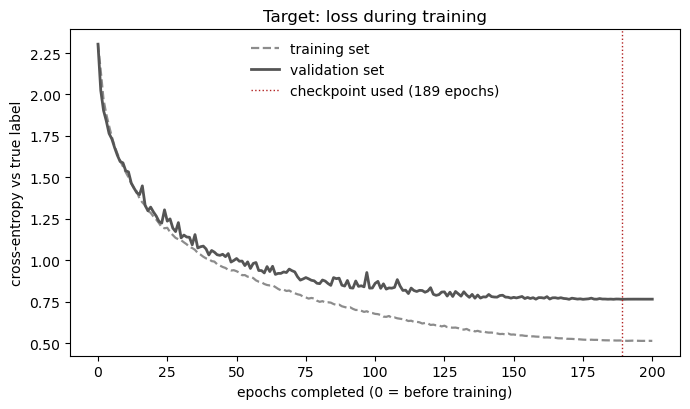

In [58]:
d = target_training
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(d["epochs_completed"], d["train_ce"], color="#8c8c8c", lw=1.6, ls="--", label="training set")
ax.plot(d["epochs_completed"], d["val_ce"], color=TARGET_COLOR, lw=2, label="validation set")
if TARGET_BEST_EPOCH is not None:
    ax.axvline(TARGET_BEST_EPOCH, color="#b22222", lw=1, ls=":", label=f"checkpoint used ({TARGET_BEST_EPOCH} epochs)")
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("cross-entropy vs true label")
ax.set_title("Target: loss during training")
ax.legend(frameon=False)
plt.tight_layout()
save(fig, "fig0_1_target_loss")
plt.show()

Findings: validation CE loss plteaued at 0.774 at best epoch (189/200), while training CE loss keeps decreasing to around 0.52 at last epoch, slight overfitting (no image augmentation added during target training).

### Figure 0.2 — Target: accuracy on training vs validation images

- **Question**: how much does the target memorize its training images?
- **Plotted**: `target_training.csv` — `train_accuracy_eval` (dots, measured every 10 epochs) and `val_accuracy` vs `epochs_completed`; prediction at t19.
- **How to read**: the gap between the two = memorization. It matters because the students are trained on the same training images: the larger the gap, the closer the target's answers on those images are to the true labels.

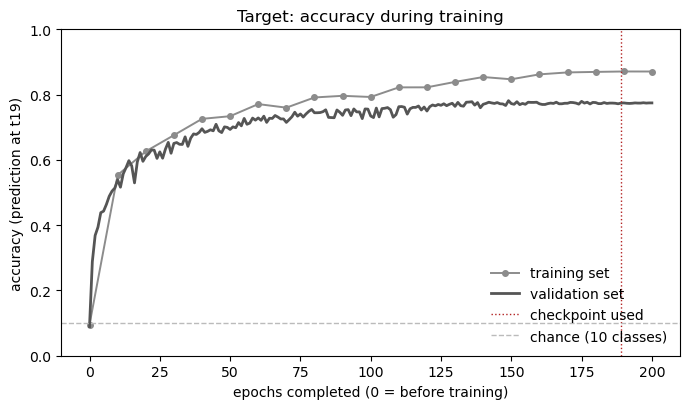

In [59]:
d = target_training
tr = d.dropna(subset=["train_accuracy_eval"])
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(tr["epochs_completed"], tr["train_accuracy_eval"], color="#8c8c8c", lw=1.4, marker="o", ms=4, label="training set")
ax.plot(d["epochs_completed"], d["val_accuracy"], color=TARGET_COLOR, lw=2, label="validation set")
if TARGET_BEST_EPOCH is not None:
    ax.axvline(TARGET_BEST_EPOCH, color="#b22222", lw=1, ls=":", label="checkpoint used")
ax.axhline(0.1, color="#bbbbbb", lw=1, ls="--", label="chance (10 classes)")
ax.set_ylim(0, 1)
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("accuracy (prediction at t19)")
ax.set_title("Target: accuracy during training")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
save(fig, "fig0_2_target_accuracy")
plt.show()

Finding: accuracy on training set at the end is about 0.87, vs. validation set around 0.775.

### Figure 0.3 — Target: accuracy at each timestep (test set)

- **Question**: how does the target's recognition develop over the 20 timesteps of one image presentation?
- **Plotted**: `test_behavior.csv`, `model == "target"` — `accuracy` vs `timestep`.
- **How to read**: the recurrent dynamics at work — how fast the target reaches its final answer. Its answer at t19 is the label the students learn.

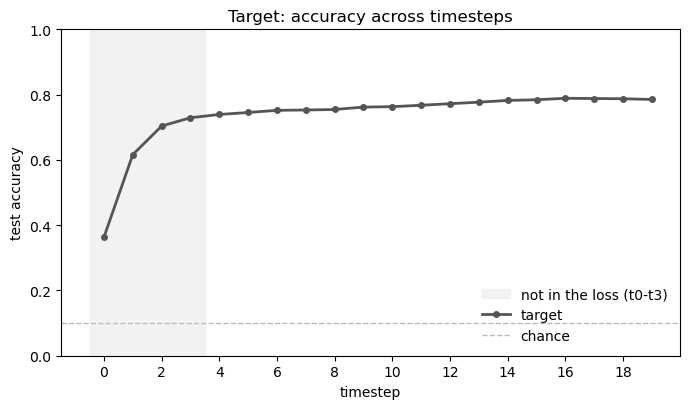

In [60]:
d = test_behavior[test_behavior["model"] == "target"]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0, label="not in the loss (t0-t3)")
ax.plot(d["timestep"], d["accuracy"], color=TARGET_COLOR, lw=2, marker="o", ms=4, label="target")
ax.axhline(0.1, color="#bbbbbb", lw=1, ls="--", label="chance")
ax.set_ylim(0, 1)
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel("test accuracy")
ax.set_title("Target: accuracy across timesteps")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
save(fig, "fig0_3_target_accuracy_by_timestep")
plt.show()

Finding: target test accuracy plateaued around epoch 6, and the last-time-step test accuracy is 0.785.

## 1 — Summary table (test set, timestep 19)

Mean ± standard deviation over the 3 seeds. Source: `summary.csv`.

In [61]:
cols = ["accuracy", "same_answer_as_target", "ce_vs_target_answer", "cka_V1", "cka_V4", "cka_IT"]
s = summary[summary["condition"] != "target"]
mean = s.groupby("condition")[cols].mean().reindex(ORDER)
std = s.groupby("condition")[cols].std().reindex(ORDER)
table = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
table.index = [LABELS[c] for c in table.index]
target_acc = summary.loc[summary["condition"] == "target", "accuracy"]
print(f"Target accuracy at t19: {target_acc.iloc[0]:.3f}" if len(target_acc) else "")
table

Target accuracy at t19: 0.785


,accuracy,same_answer_as_target,ce_vs_target_answer,cka_V1,cka_V4,cka_IT
Control (CE only),0.763 ± 0.002,0.856 ± 0.007,0.459 ± 0.019,0.958 ± 0.009,0.835 ± 0.027,0.843 ± 0.01
"IT, w=1",0.764 ± 0.002,0.885 ± 0.004,0.313 ± 0.007,0.957 ± 0.016,0.931 ± 0.02,0.987 ± 0.0
"IT, w=0.1",0.772 ± 0.002,0.893 ± 0.001,0.321 ± 0.005,0.922 ± 0.038,0.948 ± 0.0,0.977 ± 0.0
"V1+V4+IT, 0.1 each",0.769 ± 0.002,0.898 ± 0.001,0.281 ± 0.002,1.0 ± 0.0,0.994 ± 0.0,0.983 ± 0.0
"V1+V4+IT, 0.1 total",0.769 ± 0.002,0.89 ± 0.002,0.317 ± 0.009,1.0 ± 0.0,0.99 ± 0.0,0.97 ± 0.0
"IT at t2/6/12/19, 0.1 total",0.77 ± 0.003,0.887 ± 0.002,0.353 ± 0.008,0.957 ± 0.009,0.951 ± 0.005,0.968 ± 0.001


Finding: 
- All student models that were aligned to the target model earned higher accuracy (w.r.t. the ground truth labels) than the control model, with the highest one being IT, w=0.1 config. But the differences were very small compared to the std. 
- All student models have higher same_answer_as_target scores (namely, accuracy w.r.t. target model pseudo labels). 
- All student models have lower CE loss w.r.t target pseudo labels.
- CKA alignment:
    - Control model's v1_cka is as high as 0.958, showing that v1 layer is the easiest to learn (makes sense since it's close to the input layer)

## 2 — Which layers are aligned

Conditions compared: control, **IT** (w=0.1), **V1+V4+IT with the same total weight** (0.1), and V1+V4+IT with 0.1 each (0.3 total). "IT, w=0.1" vs "V1+V4+IT, 0.1 total" differ only in *where* the alignment is applied.

## **Overall Findings**

Each layer's state at a given timestep depends on 
- (1) **The input arriving through the feedforward pathway**
    - Both the target, student, and control models share the same architecture, data, and task, so all models share similar feedforward features, therefore all students/control resemble the target well in early, mainly feedforward timesteps (from t1 to t6)
- (2) **How much recurrence and feedback have accumulated**
    - After around t8, each layer's state depends more and more on recurrence and feedback rather than on the feedforward input alone. These feedback and recurrence signals are not guaranteed to match the target's (e.g. if only IT is aligned), which might result in divergence from the target
- (3) **How far away the current location is from the alignment location**
    - Aligning a single point (e.g. IT at t19) constrains the dynamics only locally, and its effect fades with distance **across layers**: strong at IT, weaker at V4 (IT's direct input), absent or even reversed at V1
    - It also fades with distance **across time**: strong near t19, weak in the middle timesteps, where IT dips


### Figure 2.1 — V1: similarity to the target at each timestep (test set)

- **Question**: how close is each student's V1 to the target's V1, and at which timesteps?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "V1"` — `cka` vs `timestep`. Grey band: `comparison == "control_vs_control"` (range over the 3 pairs of control seeds).
- **How to read**: the alignment terms act at t19 (dotted line); a gap at earlier timesteps means the alignment spread through the dynamics. Values above the grey band: the student is closer to the target than two independently seeded controls are to each other.

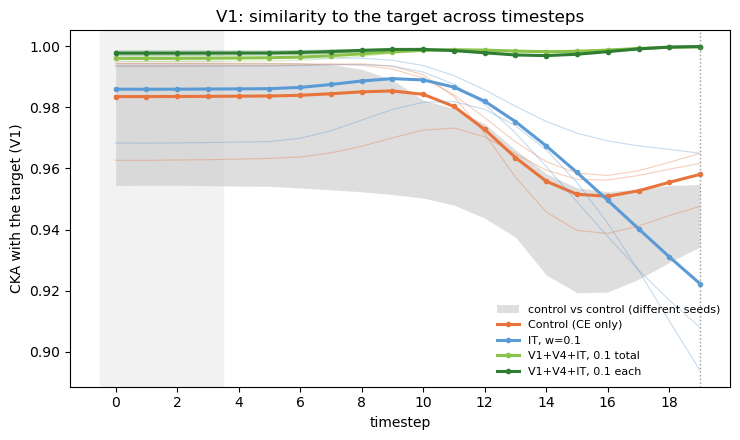

In [62]:
LAYER = "V1"
CONDITIONS = ["control", "IT_w0p1", "V1V4IT_total0p1", "V1V4IT_w0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.axvline(LAST_T, color="#999999", lw=1, ls=":")
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER}: similarity to the target across timesteps")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
save(fig, f"fig2_1_{LAYER}_cka_by_timestep")
plt.show()

Finding: 
- The two aligned configurations, v1v4IT 0.1 total or 0.1 each, aligned with target v1 almost perfectly across all timesteps.
- IT, w=0.1's v1 alignment is pretty stable during the feedforward stage (from t1 to t6), and starting from t6 to t8, as the feedback signals coming from v4 are added, v1 activations starts to diverge from the target; not quite sure if this is the effect of feedback signals coming from unaligned v4 or the fact that we aligned IT at the last timestep, which might alter the later dynamics of v1.

### Figure 2.2 — V4: similarity to the target at each timestep (test set)

- **Question**: how close is each student's V4 to the target's V4, and at which timesteps?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "V4"` — `cka` vs `timestep`. Grey band: `comparison == "control_vs_control"` (range over the 3 pairs of control seeds).
- **How to read**: the alignment terms act at t19 (dotted line); a gap at earlier timesteps means the alignment spread through the dynamics. Values above the grey band: the student is closer to the target than two independently seeded controls are to each other.

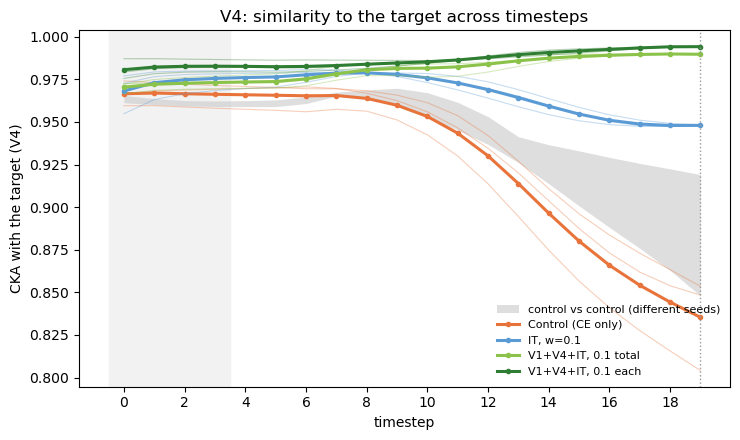

In [63]:
LAYER = "V4"
CONDITIONS = ["control", "IT_w0p1", "V1V4IT_total0p1", "V1V4IT_w0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.axvline(LAST_T, color="#999999", lw=1, ls=":")
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER}: similarity to the target across timesteps")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
save(fig, f"fig2_2_{LAYER}_cka_by_timestep")
plt.show()

V4 provides direct input to the IT layer, so matching IT at t19 requires a more target-like input from v4 around t19; this might explain why in later timesteps, v4 is more aligned with target model compared to v1.

### Figure 2.3 — IT: similarity to the target at each timestep (test set)

- **Question**: how close is each student's IT to the target's IT, and at which timesteps?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "IT"` — `cka` vs `timestep`. Grey band: `comparison == "control_vs_control"` (range over the 3 pairs of control seeds).
- **How to read**: the alignment terms act at t19 (dotted line); a gap at earlier timesteps means the alignment spread through the dynamics. Values above the grey band: the student is closer to the target than two independently seeded controls are to each other.

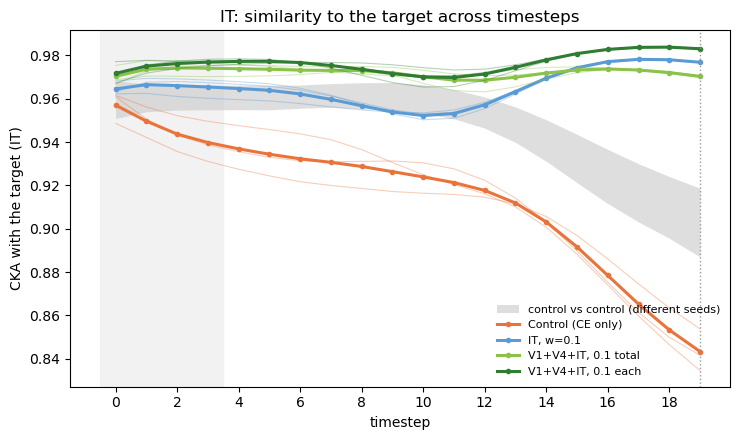

In [64]:
LAYER = "IT"
CONDITIONS = ["control", "IT_w0p1", "V1V4IT_total0p1", "V1V4IT_w0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.axvline(LAST_T, color="#999999", lw=1, ls=":")
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER}: similarity to the target across timesteps")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
save(fig, f"fig2_3_{LAYER}_cka_by_timestep")
plt.show()

- For the two green configurations (three layers aligned, t19 ), their IT alignment is surprisingly worse compared to V1, V4; 
    - This might mean that it is naturally harder to align high-level layers, where inputs have gone through rounds of preprocessing and transformations 
- For the blue configuration (IT only, t19), because now it is the closest to the alignment region, the activities are similar to the target model, especially at the alignment timestep t19
- For the control model, it's divergence from the target model accumulates throughout different layers, and in the IT layer it diverges from the target starting t0, aka starting with the feedforward timesteps.

## 3 — Which timesteps are aligned

Conditions compared: control, **IT at t19** (w=0.1), **IT at t2, t6, t12 and t19** (0.025 each, same total weight 0.1). The two aligned conditions differ only in *when* the alignment is applied.

### Figure 3.1 — IT: similarity to the target at each timestep (test set)

- **Question**: does aligning IT at several timesteps keep it close to the target throughout the dynamics, compared with aligning it only at the end?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "IT"` — `cka` vs `timestep`. Purple dotted lines: the four aligned timesteps (t19 is also the only one for "IT, w=0.1"). Grey band: control vs control.
- **How to read**: compare the two aligned conditions between the aligned timesteps — does the multi-timestep student stay high in between, or only at the four constrained points?

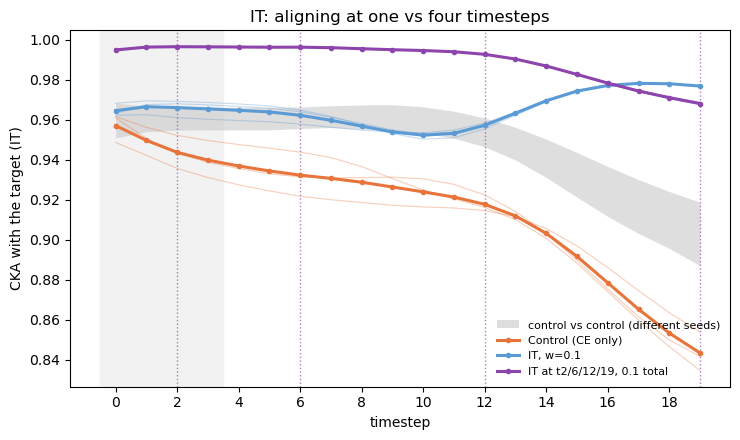

In [67]:
LAYER = "IT"
CONDITIONS = ["control", "IT_w0p1", "IT_multiT_total0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for t in D_TIMESTEPS:
    ax.axvline(t, color=COLORS["IT_multiT_total0p1"], lw=1, ls=":", alpha=0.7)
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel("CKA with the target (IT)")
ax.set_title("IT: aligning at one vs four timesteps")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
save(fig, "fig3_1_IT_cka_one_vs_four_timesteps")
plt.show()

- When aligning at multiple timesteps, the purple curve better resembles target across all timesteps, except at timesteps 16 to 19, might be because at t19, the weight given to CKA is 0.025, compared to IT, w=0.1, the weight is 0.1

### Figure 3.2 — Where in time each condition's alignment lands (IT, heatmap)

- **Question**: for every condition at once — at which timesteps did IT move toward the target?
- **Plotted**: `test_cka.csv`, `comparison == "student_vs_target"`, `layer == "IT"` — each cell: CKA of the condition minus CKA of the control of the same seed, averaged over the 3 seeds. Rows = conditions, columns = timesteps. Black boxes: the timesteps where IT is in that condition's loss.
- **How to read**: red = closer to the target than the control, blue = further away, white = no difference.

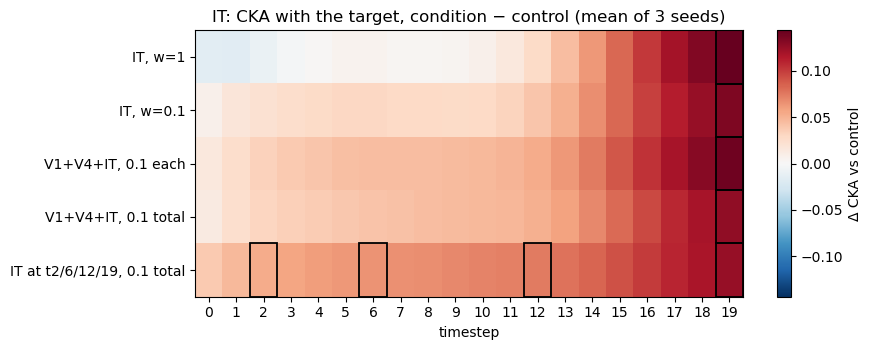

In [68]:
LAYER = "IT"
CONDITIONS = ["IT_w1", "IT_w0p1", "V1V4IT_w0p1", "V1V4IT_total0p1", "IT_multiT_total0p1"]
ALIGNED_TIMESTEPS = {"IT_w1": [19], "IT_w0p1": [19], "V1V4IT_w0p1": [19], "V1V4IT_total0p1": [19],
                     "IT_multiT_total0p1": D_TIMESTEPS}

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
control = d[d["condition"] == "control"].set_index(["seed", "timestep"])["cka"]
M = np.full((len(CONDITIONS), T), np.nan)
for i, cond in enumerate(CONDITIONS):
    delta = d[d["condition"] == cond].set_index(["seed", "timestep"])["cka"] - control
    mean = delta.groupby(level="timestep").mean()
    M[i, mean.index.astype(int)] = mean.values
lim = np.nanmax(np.abs(M))

fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(M, aspect="auto", cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim))
for i, cond in enumerate(CONDITIONS):
    for t in ALIGNED_TIMESTEPS[cond]:
        ax.add_patch(Rectangle((t - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="black", lw=1.3))
ax.set_yticks(range(len(CONDITIONS)))
ax.set_yticklabels([LABELS[c] for c in CONDITIONS])
ax.set_xticks(range(T))
ax.set_xlabel("timestep")
ax.set_title("IT: CKA with the target, condition − control (mean of 3 seeds)")
fig.colorbar(im, ax=ax, label="Δ CKA vs control")
plt.tight_layout()
save(fig, "fig3_2_heatmap_delta_IT_cka")
plt.show()

$$
\Delta_{c,t} \;=\; \frac{1}{3}\sum_{s \in \{2723,\,2724,\,2725\}} \Big[\, \mathrm{CKA}\big(\mathrm{IT}^{c,s}_t,\ \mathrm{IT}^{\mathrm{target}}_t\big) \;-\; \mathrm{CKA}\big(\mathrm{IT}^{\mathrm{control},s}_t,\ \mathrm{IT}^{\mathrm{target}}_t\big) \Big]
$$

where $c$ is the condition, $t$ the timestep and $s$ the seed; $\mathrm{IT}^{c,s}_t$ is the IT activity at timestep $t$ of the student of condition $c$ trained with seed $s$, over all test images.

### Figure 3.3 — The impact on V1, V4, when aligning multiple timesteps on IT

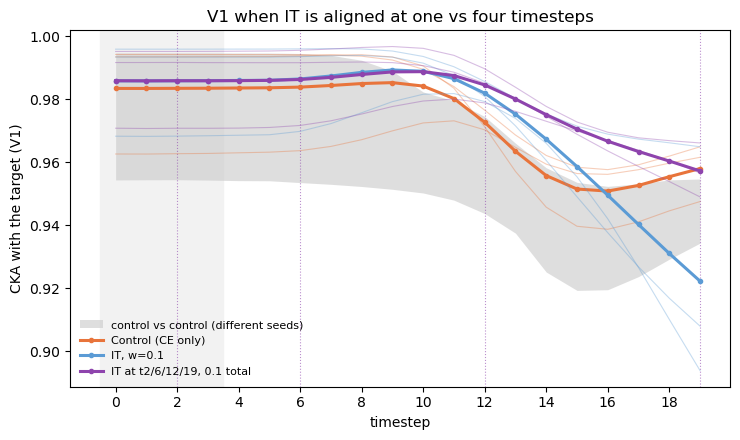

In [80]:
LAYER = "V1"
CONDITIONS = ["control", "IT_w0p1", "IT_multiT_total0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for t in D_TIMESTEPS:
    ax.axvline(t, color=COLORS["IT_multiT_total0p1"], lw=0.8, ls=":", alpha=0.6)
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER} when IT is aligned at one vs four timesteps")
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
save(fig, f"fig3_3a_{LAYER}_IT_one_vs_four_timesteps")
plt.show()

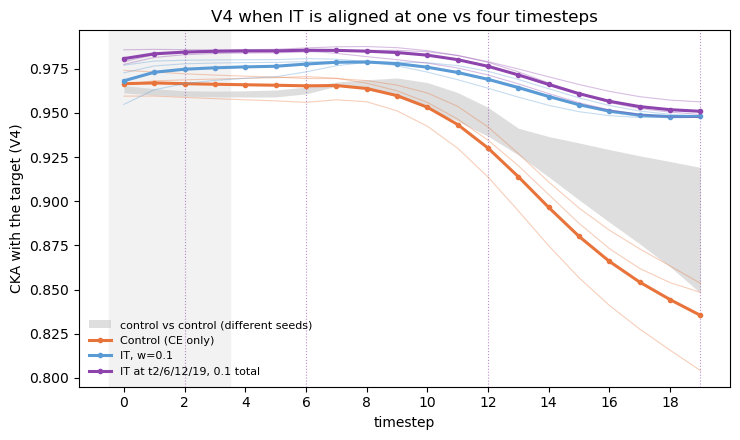

In [81]:
LAYER = "V4"
CONDITIONS = ["control", "IT_w0p1", "IT_multiT_total0p1"]

d = test_cka[(test_cka["comparison"] == "student_vs_target") & (test_cka["layer"] == LAYER)]
base = test_cka[(test_cka["comparison"] == "control_vs_control") & (test_cka["layer"] == LAYER)]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axvspan(-0.5, CE_FIRST_T - 0.5, color="#f2f2f2", zorder=0)
if len(base):
    b = base.groupby("timestep")["cka"]
    ax.fill_between(b.min().index, b.min(), b.max(), color=BASELINE_COLOR, alpha=0.6, lw=0,
                    label="control vs control (different seeds)")
for t in D_TIMESTEPS:
    ax.axvline(t, color=COLORS["IT_multiT_total0p1"], lw=0.8, ls=":", alpha=0.6)
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["timestep"], ds["cka"], color=COLORS[cond], lw=0.8, alpha=0.35)
    mean = dc.groupby("timestep")["cka"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2.2, marker="o", ms=3, label=LABELS[cond])
ax.set_xticks(range(0, T, 2))
ax.set_xlabel("timestep")
ax.set_ylabel(f"CKA with the target ({LAYER})")
ax.set_title(f"{LAYER} when IT is aligned at one vs four timesteps")
ax.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
save(fig, f"fig3_3b_{LAYER}_IT_one_vs_four_timesteps")
plt.show()

## 4 — How strongly to align

Conditions compared: IT with weight 1 vs 0.1; V1+V4+IT with 0.1 each vs 0.1 in total.

### Figure 4.1 — Alignment vs recognition: is there a cost?

- **Question**: do the students that are most aligned with the target pay for it in accuracy?
- **Plotted**: `summary.csv` (test set, t19) — x: `cka_IT`, y: `accuracy`. Small dots = seeds, large dots = mean of each condition. Dashed line: the target's accuracy.
- **How to read**: points further right are more aligned; points lower are less accurate. A cost would show as a downward trend from left to right.

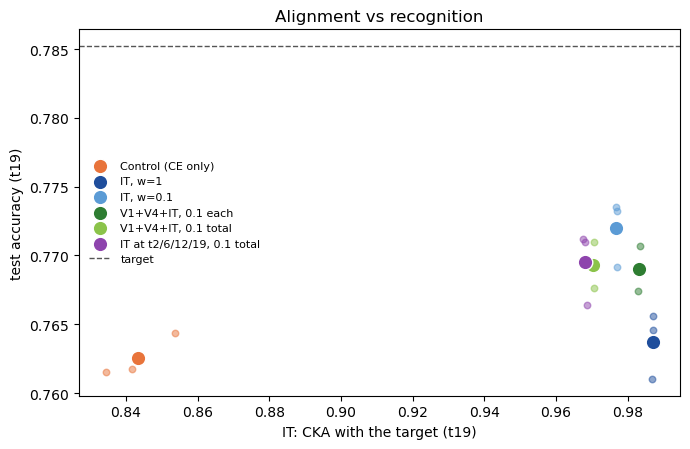

In [72]:
CONDITIONS = ORDER
X, Y = "cka_IT", "accuracy"

s = summary
fig, ax = plt.subplots(figsize=(7, 4.6))
for cond in CONDITIONS:
    sc = s[s["condition"] == cond]
    ax.scatter(sc[X], sc[Y], color=COLORS[cond], s=22, alpha=0.5)
    ax.scatter([sc[X].mean()], [sc[Y].mean()], color=COLORS[cond], s=110, edgecolor="white", lw=1, label=LABELS[cond])
tgt = s.loc[s["condition"] == "target", Y]
if len(tgt):
    ax.axhline(tgt.iloc[0], color=TARGET_COLOR, lw=1, ls="--", label="target")
ax.set_xlabel("IT: CKA with the target (t19)")
ax.set_ylabel("test accuracy (t19)")
ax.set_title("Alignment vs recognition")
ax.legend(frameon=False, fontsize=8, loc="best")
plt.tight_layout()
save(fig, "fig4_1_alignment_vs_accuracy")
plt.show()

Test accuracy against **ground truth** labels. 
- All aligned models have higher accuracy compared to the control model
- Within the aligned group, IT, w=1, aka the configuration with the highest CKA weight achoeved relatively lower accuracy, similar to the control m odel, but it has highest IT alignment.
- There is a mild trade-off between CAK alignment weight and accuracy.

### Figure 4.2 — During training: loss on the target's answers (IT weight 1 vs 0.1)

- **Question**: does a stronger alignment slow down or limit learning the target's answers?
- **Plotted**: `student_training.csv` — `val_ce` (cross-entropy vs the target's final answer, validation set, averaged over timesteps 4–19) vs `epochs_completed`.

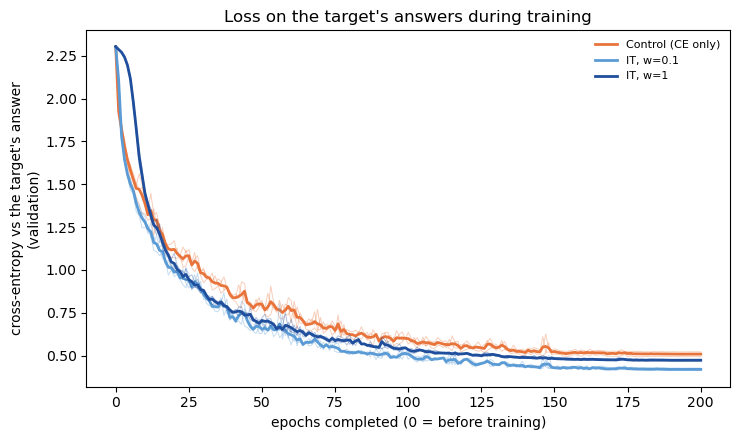

In [73]:
CONDITIONS = ["control", "IT_w0p1", "IT_w1"]

d = student_training
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["epochs_completed"], ds["val_ce"], color=COLORS[cond], lw=0.7, alpha=0.35)
    mean = dc.groupby("epochs_completed")["val_ce"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2, label=LABELS[cond])
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("cross-entropy vs the target's answer\n(validation)")
ax.set_title("Loss on the target's answers during training")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
save(fig, "fig4_2_val_ce")
plt.show()

### Figure 4.3 — During training: loss on the target's answers (V1+V4+IT, 0.1 total vs 0.1 each)

- **Question**: does a stronger alignment slow down or limit learning the target's answers?
- **Plotted**: `student_training.csv` — `val_ce` (cross-entropy vs the target's final answer, validation set, averaged over timesteps 4–19) vs `epochs_completed`.

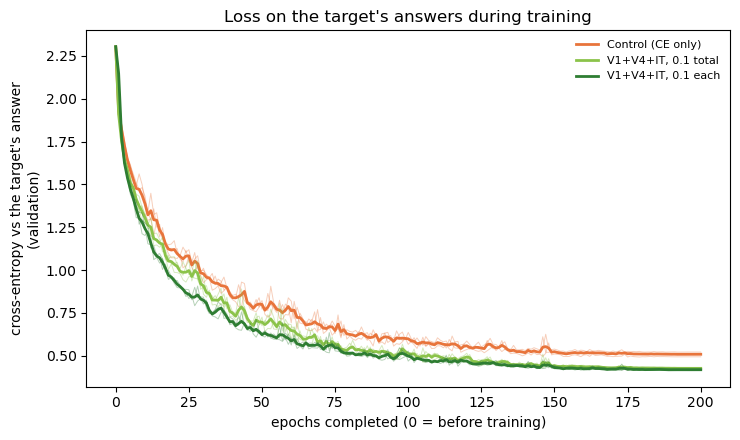

In [74]:
CONDITIONS = ["control", "V1V4IT_total0p1", "V1V4IT_w0p1"]

d = student_training
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["epochs_completed"], ds["val_ce"], color=COLORS[cond], lw=0.7, alpha=0.35)
    mean = dc.groupby("epochs_completed")["val_ce"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2, label=LABELS[cond])
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("cross-entropy vs the target's answer\n(validation)")
ax.set_title("Loss on the target's answers during training")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
save(fig, "fig4_3_val_ce")
plt.show()

## Appendix — Training details

Checks that training behaved as intended. Not needed to follow the results above.

### Figure A.1 — Loss on the target's answers (control, IT at t19, IT at four timesteps)

Same as Figures 4.2 / 4.3 for the conditions of section 3. Source: `student_training.csv`, `val_ce`.

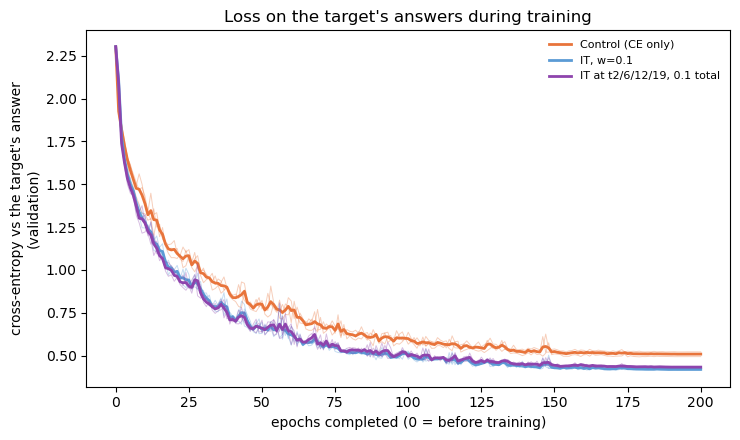

In [75]:
CONDITIONS = ["control", "IT_w0p1", "IT_multiT_total0p1"]

d = student_training
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cond in CONDITIONS:
    dc = d[d["condition"] == cond]
    for seed, ds in dc.groupby("seed"):
        ax.plot(ds["epochs_completed"], ds["val_ce"], color=COLORS[cond], lw=0.7, alpha=0.35)
    mean = dc.groupby("epochs_completed")["val_ce"].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2, label=LABELS[cond])
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("cross-entropy vs the target's answer\n(validation)")
ax.set_title("Loss on the target's answers during training")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
save(fig, "figA_1_val_ce")
plt.show()

### Figure A.2 — IT similarity to the target during training (t19)

- **Plotted**: `student_training.csv` — `val_cka_IT_t19` (batch CKA, validation) vs `epochs_completed`, all conditions, mean over seeds only.
- **How to read**: how quickly each condition aligns IT. At epoch 0 all students of one seed are identical, so the curves start from the same point.

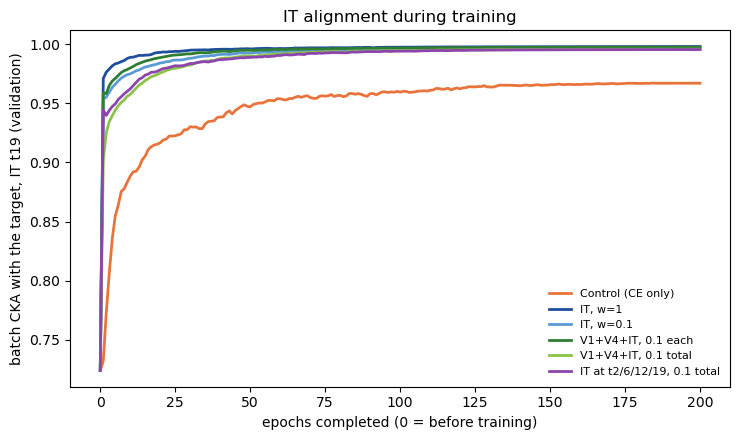

In [76]:
CONDITIONS = ORDER
COLUMN = "val_cka_IT_t19"

d = student_training
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cond in CONDITIONS:
    mean = d[d["condition"] == cond].groupby("epochs_completed")[COLUMN].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=2, label=LABELS[cond])
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("batch CKA with the target, IT t19 (validation)")
ax.set_title("IT alignment during training")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout()
save(fig, "figA_2_training_IT_cka")
plt.show()

### Figure A.3 — Balance between the alignment terms and the CE term

- **Plotted**: `student_training.csv` — `grad_ratio_cka_to_ce` vs `epochs_completed` (log scale), aligned conditions, mean over seeds.
- **How to read**: above 1 (dashed) = the alignment terms dominate the parameter update. The gradient of log(1 − CKA) grows like weight / (1 − CKA), so the ratio tends to rise as CKA approaches 1.

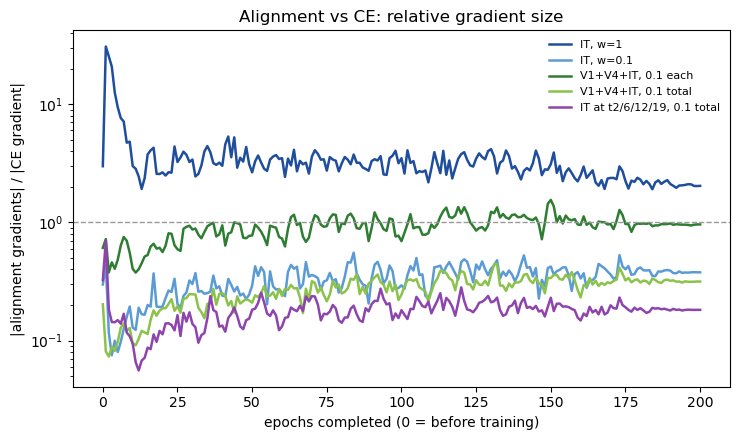

In [77]:
CONDITIONS = [c for c in ORDER if c != "control"]
COLUMN = "grad_ratio_cka_to_ce"

d = student_training
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cond in CONDITIONS:
    mean = d[d["condition"] == cond].groupby("epochs_completed")[COLUMN].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=1.8, label=LABELS[cond])
ax.axhline(1, color="#999999", lw=1, ls="--")
ax.set_yscale("log")
ax.set_xlabel("epochs completed (0 = before training)")
ax.set_ylabel("|alignment gradients| / |CE gradient|")
ax.set_title("Alignment vs CE: relative gradient size")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
save(fig, "figA_3_gradient_ratio")
plt.show()

### Figure A.4 — Gradient size per training step

- **Plotted**: `student_training.csv` — `train_grad_norm` (mean over the steps of each epoch, before clipping) vs `epochs_completed`, mean over seeds. Dashed: the clipping threshold (500).
- **How to read**: all curves far below the threshold = clipping never changed an update (also see `train_clip_fraction`).

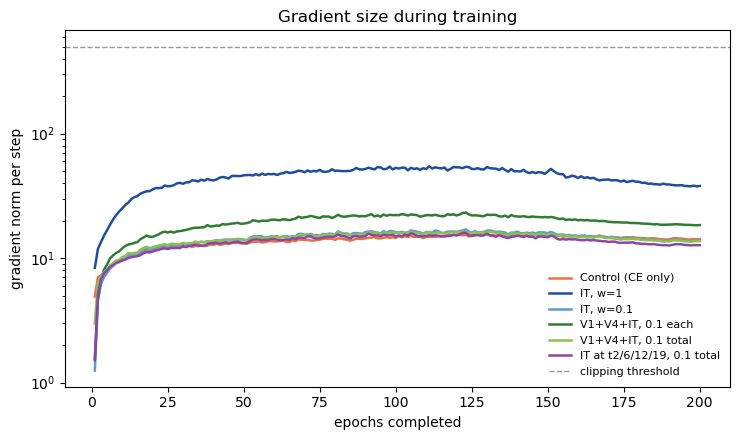

largest fraction of clipped steps in any epoch of any run: 0.0


In [78]:
CONDITIONS = ORDER
COLUMN = "train_grad_norm"
CLIP_THRESHOLD = 500

d = student_training
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for cond in CONDITIONS:
    mean = d[d["condition"] == cond].groupby("epochs_completed")[COLUMN].mean()
    ax.plot(mean.index, mean.values, color=COLORS[cond], lw=1.8, label=LABELS[cond])
ax.axhline(CLIP_THRESHOLD, color="#999999", lw=1, ls="--", label="clipping threshold")
ax.set_yscale("log")
ax.set_xlabel("epochs completed")
ax.set_ylabel("gradient norm per step")
ax.set_title("Gradient size during training")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
save(fig, "figA_4_gradient_norm")
plt.show()
print("largest fraction of clipped steps in any epoch of any run:", d["train_clip_fraction"].max())